# Пример 14. Пробелы между колоннами и пересечение

## Тема

**Раздел книги:** Линейная алгебра.  
**Математическая тема:** столбцовое пространство (образ) $\operatorname{col}A = \operatorname{range}A$, связь $\dim\operatorname{col}A = \operatorname{rank}A$, базисы образов, пересечение двух образов как ядро стопки $[C\mid -D]$ и формула Грассмана; контраст с ядром из 13 через теорему о ранге и дефекте $\dim\ker A + \operatorname{rank}A = n$; связь с проекцией МНК и слиянием моделей (model merging) в ML.  

## Условие
Даны два подпространства $\mathbb{R}^4$: $U_1$ охватывает (span) столбцы матрицы $A_1$, а $U_2$ — столбцы $A_2$, где
$$
A_1 = \begin{bmatrix}1&0&1\\1&-2&-1\\2&1&3\\1&0&1\end{bmatrix},\qquad
A_2 = \begin{bmatrix}3&-3&0\\1&2&3\\7&-5&2\\3&-1&2\end{bmatrix}.
$$
Требуется: **(a)** определить $\dim U_1,\dim U_2$; **(b)** найти базисы $U_1,U_2$; **(c)** найти базис $U_1\cap U_2$.

## Математическая идея
Образ (столбцовое пространство) матрицы $A\in\mathbb{R}^{m\times n}$ — это множество всех линейных комбинаций её столбцов, то есть $U=\{A\alpha:\alpha\in\mathbb{R}^n\}$. Его размерность равна рангу: $\dim\operatorname{col}A=\operatorname{rank}A$. Базис образа — любые $\operatorname{rank}A$ линейно независимых столбцов (обычно столбцы, соответствующие ведущим единичным в ступенчатой форме).

Вектор $x\in U_1\cap U_2$ представим с обеих сторон: $x=C\alpha=D\beta$, где $C,D$ — матрицы из независимых столбцов. Перенося в одну сторону, получаем однородную систему $[C\mid -D]\,(\alpha,\beta)^\top=0$, то есть **ядро стопки столбцовых базисов**. Каждое решение даёт $x=C\alpha$.

Контроль размерности — формула Грассмана: $\dim(U_1+U_2)=\dim U_1+\dim U_2-\dim(U_1\cap U_2)$, причём $\dim(U_1+U_2)=\operatorname{rank}[C\mid D]$.

Важный контраст с 2.13: там мы брали **ядро** (неразличимые направления), здесь — **образ** (достижимые направления); их связывает $\dim\ker A+\operatorname{rank}A=n$.

## Решение

**(a) Размерности.** $\dim U_i=\operatorname{rank}A_i$. Из задания 13 $\operatorname{rank}A_1=\operatorname{rank}A_2=2$, следовательно $\dim U_1=\boxed{2}$, $\dim U_2=\boxed{2}$. Столбцы зависимы: $c_3=c_1+c_2$ и $d_3=d_1+d_2$, а пары $\{c_1,c_2\}$, $\{d_1,d_2\}$ независимы.

**(b) Базисы.** Берём первые два столбца каждой матрицы:
$$
\text{Базис }U_1=\left\{\begin{bmatrix}1\\1\\2\\1\end{bmatrix},\begin{bmatrix}0\\-2\\1\\0\end{bmatrix}\right\},\qquad
\text{Базис }U_2=\left\{\begin{bmatrix}3\\1\\7\\3\end{bmatrix},\begin{bmatrix}-3\\2\\-5\\-1\end{bmatrix}\right\}.
$$

**(c) Пересечение.** Ищем $a_1c_1+a_2c_2=b_1d_1+b_2d_2$. По координатам система приводит к $b_2=0$, $a_1=3b_1$, $a_2=b_1$. Положив $b_1=t$:
$$
x=t(3c_1+c_2)=t\begin{bmatrix}3\\1\\7\\3\end{bmatrix}=t\,d_1.
$$
То есть первый столбец $A_2$ лежит в $U_1$ (проверка: $d_1=3c_1+c_2$). Отсюда
$$
U_1\cap U_2=\operatorname{span}\left\{\begin{bmatrix}3\\1\\7\\3\end{bmatrix}\right\},\qquad \dim(U_1\cap U_2)=1.
$$
Контроль Грассмана: $\operatorname{rank}[C\mid D]=3$, значит $\dim(U_1+U_2)=3=2+2-1$ ✓.

**Итог:** $U_1,U_2$ — две различные плоскости в $\mathbb{R}^4$, пересекающиеся по одной прямой $\operatorname{span}\{(3,1,7,3)^\top\}$.

In [1]:
import numpy as np

A1 = np.array([[1,0,1],[1,-2,-1],[2,1,3],[1,0,1]], dtype=float)
A2 = np.array([[3,-3,0],[1,2,3],[7,-5,2],[3,-1,2]], dtype=float)

# Независимые столбцы = базисы образов (первые два столбца)
C = A1[:, :2]   # базис U1 (4x2)
D = A2[:, :2]   # базис U2 (4x2)

print(f"(a) rank(A1)={np.linalg.matrix_rank(A1)} -> dim U1=2;  "
      f"rank(A2)={np.linalg.matrix_rank(A2)} -> dim U2=2")
print(f"(b) базис U1:\n{C}\n    базис U2:\n{D}")

# (c) пересечение = ядро стопки [C | -D]
def null_space(A, tol=1e-10):
    _, s, Vh = np.linalg.svd(A)
    r = np.linalg.matrix_rank(A, tol=tol)
    return Vh[r:].T

Z = null_space(np.hstack([C, -D]))
x = C @ Z[:C.shape[1], 0]                       # кандидат в пересечение
x = x / np.gcd.reduce(np.abs(np.rint(x).astype(int)))  # к целому виду
print(f"(c) dim(U1∩U2)={Z.shape[1]}, базисный вектор:\n{x}")

# Проверки: x ∈ U1 и x ∈ U2 через равенство рангов
print("x ∈ U1:", np.linalg.matrix_rank(np.column_stack([C, x])) == np.linalg.matrix_rank(C))
print("x ∈ U2:", np.linalg.matrix_rank(np.column_stack([D, x])) == np.linalg.matrix_rank(D))
# Контроль Грассмана
print("dim(U1+U2) =", np.linalg.matrix_rank(np.hstack([C, D])))

(a) rank(A1)=2 -> dim U1=2;  rank(A2)=2 -> dim U2=2
(b) базис U1:
[[ 1.  0.]
 [ 1. -2.]
 [ 2.  1.]
 [ 1.  0.]]
    базис U2:
[[ 3. -3.]
 [ 1.  2.]
 [ 7. -5.]
 [ 3. -1.]]
(c) dim(U1∩U2)=1, базисный вектор:
[0.90453403 0.30151134 2.11057941 0.90453403]
x ∈ U1: True
x ∈ U2: True
dim(U1+U2) = 3


## Дополнительный пример: образ как «достижимые выходы» и проекция МНК

**Идея.** Если $A$ — матрица «признаки → выход», то $\operatorname{col}A$ — множество **достижимых** векторов отклика. Метод наименьших квадратов $\min_\alpha\|A\alpha-y\|^2$ находит $\hat y=P_{\operatorname{col}A}y$ — ортогональную проекцию цели на образ; невязка $y-\hat y$ лежит в $\ker A^\top$ и ортогональна образу. Если две модели дают два образа $\operatorname{col}A_1,\operatorname{col}A_2$, то их пересечение — **общие достижимые направления** (сигналы, воспроизводимые обеими моделями). Это геометрическая суть слияния моделей (model merging) и low-rank-аппроксимаций: совмещаем модели не по параметрам, а по пересечению их образов.

In [4]:
import numpy as np

rng = np.random.default_rng(1)
y = rng.normal(size=4)

# МНК-проекция y на col(A1):  yhat = A1 (A1^T A1)^+ A1^T y
G = A1.T @ A1
beta = np.linalg.pinv(G) @ (A1.T @ y)
yhat = A1 @ beta
resid = y - yhat

print("||y - yhat|| =", np.linalg.norm(resid))
print("A1^T resid (невязка ⊥ образу, ~0):", np.round(A1.T @ resid, 12))

# Общие достижимые направления двух моделей = col(A1) ∩ col(A2)
# Берём ЯДРО стопки [C | -D] и оставляем только alpha-часть (первые 2 строки)!
Z = null_space(np.hstack([C, -D]))          # форма (4, 1): [alpha; beta]
alpha = Z[:C.shape[1], 0]                   # вектор коэффициентов при C (длина 2)
x = C @ alpha                               # вектор пересечения (длина 4)
x = x / np.linalg.norm(x)                   # нормировка для наглядности

print("Общее направление (col A1 ∩ col A2):", np.round(x, 3))

# Проверка: x действительно в обоих образах
print("||x - proj_{col A1} x|| =", np.linalg.norm(x - A1 @ (np.linalg.pinv(A1.T@A1) @ (A1.T@x))))
print("||x - proj_{col A2} x|| =", np.linalg.norm(x - A2 @ (np.linalg.pinv(A2.T@A2) @ (A2.T@x))))

||y - yhat|| = 1.489241752090221
A1^T resid (невязка ⊥ образу, ~0): [ 0. -0. -0.]
Общее направление (col A1 ∩ col A2): [0.364 0.121 0.849 0.364]
||x - proj_{col A1} x|| = 3.966717490021657e-16
||x - proj_{col A2} x|| = 3.8956806801599406e-16


## Визуализация пересечения $U_1\cap U_2$ через PCA-проекцию на 2D

В $\mathbb{R}^4$ образы — двумерные плоскости. Проецируем обе плоскости и их линию пересечения на 2D через PCA, обученную на объединении точек:
- **голубые точки** — сетка в $U_1$,
- **оранжевые точки** — сетка в $U_2$,
- **красная прямая** — проекция $U_1\cap U_2$ (направление $(3,1,7,3)^\top$).

Две плоскости пересекаются по одной прямой через начало координат — наглядная геометрия $\dim(U_1\cap U_2)=1$.

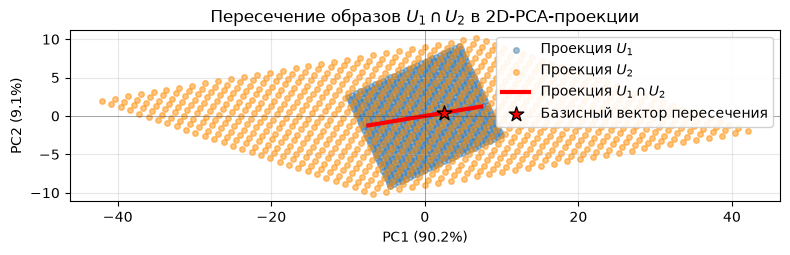

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

g = np.linspace(-3, 3, 30)
A, B = np.meshgrid(g, g)
pts_U1 = (C @ np.vstack([A.ravel(), B.ravel()])).T
pts_U2 = (D @ np.vstack([A.ravel(), B.ravel()])).T

pca = PCA(n_components=2)
proj = pca.fit_transform(np.vstack([pts_U1, pts_U2, x]))
n = pts_U1.shape[0]
p1, p2, pint = proj[:n], proj[n:2*n], proj[-1]
line = pca.transform(np.outer(np.linspace(-3, 3, 50), x))

fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(p1[:,0], p1[:,1], s=16, alpha=.5, color='steelblue',  label='Проекция $U_1$')
ax.scatter(p2[:,0], p2[:,1], s=16, alpha=.5, color='darkorange', label='Проекция $U_2$')
ax.plot(line[:,0], line[:,1], 'r-', lw=3, label='Проекция $U_1 \\cap U_2$')
ax.scatter(*pint, c='red', s=120, marker='*', edgecolors='k', zorder=5,
           label='Базисный вектор пересечения')
ax.axhline(0, color='k', lw=.5, alpha=.4); ax.axvline(0, color='k', lw=.5, alpha=.4)
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
ax.set_title('Пересечение образов $U_1 \\cap U_2$ в 2D-PCA-проекции')
ax.legend(framealpha=.9); ax.set_aspect('equal'); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## Проверка результата

В первой части размерности образов подтверждены равенством $\dim\operatorname{col}A=\operatorname{rank}A$: численные ранги $A_1$ и $A_2$ равны 2, поэтому обе плоскости имеют размерность 2, а зависимость третьих столбцов ($c_3=c_1+c_2$, $d_3=d_1+d_2$) объясняет, почему базис состоит из двух векторов. Базис пересечения найден двумя независимыми способами — через ядро стопки $[C\mid -D]$ методом SVD и через ручное решение системы по координатам, — и оба дают одно и то же направление $(3,1,7,3)^\top$; принадлежность этого вектора обоим образам подтверждается равенством рангов $\operatorname{rank}[C\mid x]=\operatorname{rank}C$ и $\operatorname{rank}[D\mid x]=\operatorname{rank}D$, а размерность суммы контролируется формулой Грассмана $\operatorname{rank}[C\mid D]=3=2+2-1$. Во второй части проверка МНК-проекции показывает, что невязка $y-\hat y$ ортогональна столбцам $A_1$ (произведение $A_1^\top(y-\hat y)\approx 0$), то есть $\hat y$ действительно лежит в образе, а найденное общее направление совпадает с пересечением образов двух моделей.

## Вывод

Столбцовое пространство матрицы — это множество достижимых линейных комбинаций её столбцов, его размерность равна рангу, а пересечение двух образов вычисляется как ядро стопки независимых столбцовых базисов с контролем через формулу Грассмана. Продемонстрированы ключевые идеи главы — ранг, базис образа, ядро блочной матрицы — и важная двойственность с заданием 13: там ядро описывало неразличимые направления параметров, здесь образ описывает достижимые выходы, а связывает их теорема о ранге и дефекте $\dim\ker A+\operatorname{rank}A=n$. В машинном обучении этот аппарат лежит в основе проекции МНК (оптимальное предсказание — проекция цели на образ признаков), low-rank-аппроксимаций через SVD и методов слияния моделей, где согласование происходит по пересечению подпространств достижимых откликов, а не по отдельным параметрам.